In [2]:
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [4]:
import os

print(os.getcwd())

C:\Users\kgowt


In [7]:
policies = pd.read_csv("dataset/policies.csv")
members = pd.read_csv("dataset/members.csv")
claims = pd.read_csv("dataset/claims.csv")
hospitals = pd.read_csv("dataset/hospitals.csv")
renewals = pd.read_csv("dataset/renewals.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [11]:
# Create dictionary containing all five datasets

datasets = {
    "Policies": policies,
    "Members": members,
    "Claims": claims,
    "Hospitals": hospitals,
    "Renewals": renewals
}

print("All five datasets added successfully!")

All five datasets added successfully!


In [12]:
# Standardise column names

for df in datasets.values():

    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

print("Column names standardised successfully!")

Column names standardised successfully!


In [13]:
for name, df in datasets.items():

    print("\n", name)
    print(df.columns.tolist())


 Policies
['policy_id', 'start_date', 'plan_type', 'sum_insured', 'annual_premium', 'city']

 Members
['member_id', 'policy_id', 'age_group', 'gender', 'pre_existing_condition']

 Claims
['claim_id', 'policy_id', 'member_id', 'claim_date', 'hospital_id', 'treatment_category', 'claim_amount', 'approved_amount', 'claim_status']

 Hospitals
['hospital_id', 'city', 'tier', 'network']

 Renewals
['policy_id', 'renewal_due_date', 'renewed', 'premium_change_percent']


In [14]:
for name, df in datasets.items():

    print("\n", name)

    print("Duplicate Rows:", df.duplicated().sum())


 Policies
Duplicate Rows: 0

 Members
Duplicate Rows: 0

 Claims
Duplicate Rows: 0

 Hospitals
Duplicate Rows: 0

 Renewals
Duplicate Rows: 0


In [15]:
# Remove duplicate policies
policies = policies.drop_duplicates(subset="policy_id")

# Remove duplicate members
members = members.drop_duplicates(subset="member_id")

# Remove duplicate claims
claims = claims.drop_duplicates(subset="claim_id")

# Remove duplicate hospitals
hospitals = hospitals.drop_duplicates(subset="hospital_id")

# Remove duplicate renewals
renewals = renewals.drop_duplicates(subset="policy_id")

In [16]:
print("Policies:", policies.duplicated(subset="policy_id").sum())

print("Members:", members.duplicated(subset="member_id").sum())

print("Claims:", claims.duplicated(subset="claim_id").sum())

print("Hospitals:", hospitals.duplicated(subset="hospital_id").sum())

print("Renewals:", renewals.duplicated(subset="policy_id").sum())

Policies: 0
Members: 0
Claims: 0
Hospitals: 0
Renewals: 0


In [17]:
for name, df in datasets.items():

    print("\n==========", name, "==========")

    print(df.isnull().sum())


========== Policies ==========
policy_id         0
start_date        0
plan_type         0
sum_insured       0
annual_premium    0
city              0
dtype: int64

========== Members ==========
member_id                 0
policy_id                 0
age_group                 0
gender                    0
pre_existing_condition    0
dtype: int64

========== Claims ==========
claim_id              0
policy_id             0
member_id             0
claim_date            0
hospital_id           0
treatment_category    0
claim_amount          0
approved_amount       0
claim_status          0
dtype: int64

========== Hospitals ==========
hospital_id    0
city           0
tier           0
network        0
dtype: int64

========== Renewals ==========
policy_id                 0
renewal_due_date          0
renewed                   0
premium_change_percent    0
dtype: int64


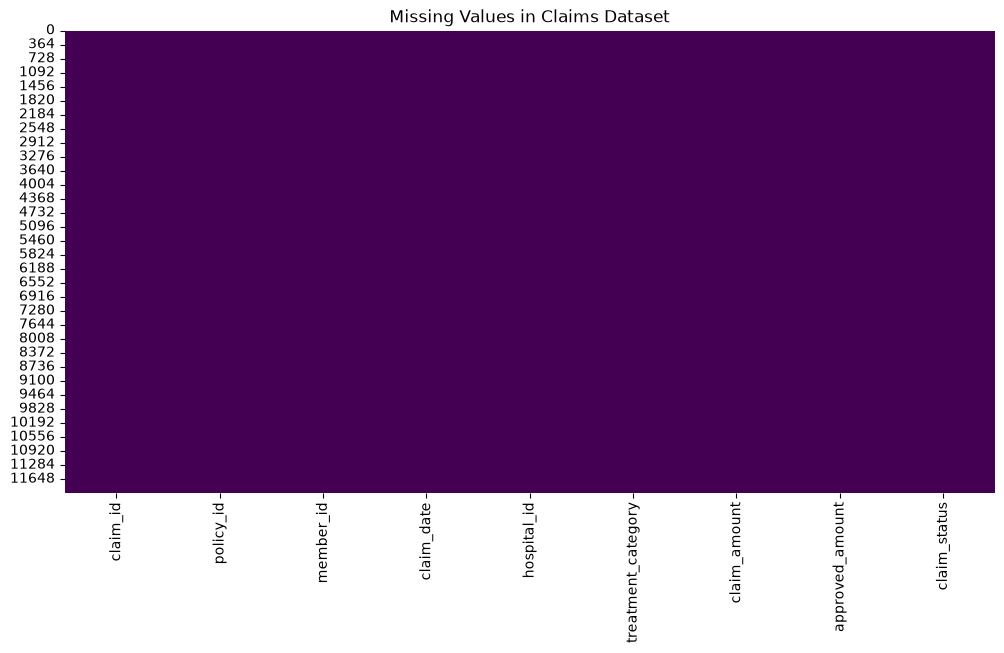

In [18]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    claims.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in Claims Dataset")

plt.show()

In [19]:
for name, df in datasets.items():

    missing = df.isnull().sum().sum()

    if missing == 0:
        print(name, ": No missing values found")
    else:
        print(name, ": Missing values =", missing)

Policies : No missing values found
Members : No missing values found
Claims : No missing values found
Hospitals : No missing values found
Renewals : No missing values found


In [20]:
# below 5 codes are for standardising

policies["plan_type"] = policies["plan_type"].str.strip().str.title()

policies["city"] = policies["city"].str.strip().str.title()

In [21]:
members["gender"] = members["gender"].str.strip().str.title()

members["pre_existing_condition"] = (
    members["pre_existing_condition"]
    .str.strip()
    .str.title()
)

In [22]:
members["gender"] = members["gender"].str.strip().str.title()

members["pre_existing_condition"] = (
    members["pre_existing_condition"]
    .str.strip()
    .str.title()
)

In [23]:
hospitals["city"] = hospitals["city"].str.strip().str.title()

hospitals["tier"] = hospitals["tier"].str.strip().str.title()

hospitals["network"] = hospitals["network"].str.strip().str.title()

In [24]:
renewals["renewed"] = renewals["renewed"].str.strip().str.title()

In [25]:
print("Plan Types:")
print(policies["plan_type"].unique())

print("\nGender:")
print(members["gender"].unique())

print("\nClaim Status:")
print(claims["claim_status"].unique())

print("\nHospital Tiers:")
print(hospitals["tier"].unique())

print("\nRenewal Status:")
print(renewals["renewed"].unique())

Plan Types:
['Family' 'Individual']

Gender:
['Male' 'Female']

Claim Status:
['Approved' 'Partially Approved' 'Rejected' 'Pending']

Hospital Tiers:
['Tier 2' 'Tier 1' 'Tier 3']

Renewal Status:
['No' 'Pending' 'Yes']


In [26]:
# Convert Date Columns into Datetime Format

policies["start_date"] = pd.to_datetime(
    policies["start_date"],
    errors="coerce"
)

In [27]:
claims["claim_date"] = pd.to_datetime(
    claims["claim_date"],
    errors="coerce"
)

In [28]:
renewals["renewal_due_date"] = pd.to_datetime(
    renewals["renewal_due_date"],
    errors="coerce"
)

In [29]:
print("Policies:")
print(policies["start_date"].dtype)

print("\nClaims:")
print(claims["claim_date"].dtype)

print("\nRenewals:")
print(renewals["renewal_due_date"].dtype)

Policies:
datetime64[ns]

Claims:
datetime64[ns]

Renewals:
datetime64[ns]


In [30]:
# Convert columns into numerical format

# Policies dataset

policies["sum_insured"] = pd.to_numeric(
    policies["sum_insured"], errors="coerce"
)

policies["annual_premium"] = pd.to_numeric(
    policies["annual_premium"], errors="coerce"
)


# Claims dataset

claims["claim_amount"] = pd.to_numeric(
    claims["claim_amount"], errors="coerce"
)

claims["approved_amount"] = pd.to_numeric(
    claims["approved_amount"], errors="coerce"
)


# Renewals dataset

renewals["premium_change_percent"] = pd.to_numeric(
    renewals["premium_change_percent"], errors="coerce"
)

print("Numerical columns converted successfully!")

Numerical columns converted successfully!


In [33]:
# Verify data types

print("Policies:")
print(policies[["sum_insured", "annual_premium"]].dtypes)

print("\nClaims:")
print(claims[["claim_amount", "approved_amount"]].dtypes)

print("\nRenewals:")
print(renewals[["premium_change_percent"]].dtypes)

Policies:
sum_insured       int64
annual_premium    int64
dtype: object

Claims:
claim_amount       int64
approved_amount    int64
dtype: object

Renewals:
premium_change_percent    float64
dtype: object


In [34]:
print("Policies:")
print(policies[["sum_insured", "annual_premium"]].isnull().sum())

print("\nClaims:")
print(claims[["claim_amount", "approved_amount"]].isnull().sum())

print("\nRenewals:")
print(renewals[["premium_change_percent"]].isnull().sum())

Policies:
sum_insured       0
annual_premium    0
dtype: int64

Claims:
claim_amount       0
approved_amount    0
dtype: int64

Renewals:
premium_change_percent    0
dtype: int64


In [35]:
# Define valid cqaategories

valid_values = {
    "plan_type": ["Individual", "Family"],

    "gender": ["Male", "Female"],

    "pre_existing_condition": ["Yes", "No"],

    "claim_status": [
        "Approved",
        "Partially Approved",
        "Rejected",
        "Pending"
    ],

    "tier": ["Tier 1", "Tier 2", "Tier 3"],

    "network": ["Yes", "No"],

    "renewed": ["Yes", "No", "Pending"]
}

In [36]:
for column, valid in valid_values.items():

    for name, df in datasets.items():

        if column in df.columns:

            invalid = df[
                ~df[column].isin(valid) & df[column].notna()
            ]

            print(
                name,
                "-",
                column,
                "- Invalid records:",
                len(invalid)
            )

Policies - plan_type - Invalid records: 0
Members - gender - Invalid records: 0
Members - pre_existing_condition - Invalid records: 0
Claims - claim_status - Invalid records: 0
Hospitals - tier - Invalid records: 0
Hospitals - network - Invalid records: 0
Renewals - renewed - Invalid records: 0


In [37]:
print("Plan Types:")
print(policies["plan_type"].unique())

print("\nGender:")
print(members["gender"].unique())

print("\nPre-existing Conditions:")
print(members["pre_existing_condition"].unique())

print("\nClaim Status:")
print(claims["claim_status"].unique())

print("\nHospital Tiers:")
print(hospitals["tier"].unique())

print("\nHospital Network:")
print(hospitals["network"].unique())

print("\nRenewal Status:")
print(renewals["renewed"].unique())

Plan Types:
['Family' 'Individual']

Gender:
['Male' 'Female']

Pre-existing Conditions:
['No' 'Yes']

Claim Status:
['Approved' 'Partially Approved' 'Rejected' 'Pending']

Hospital Tiers:
['Tier 2' 'Tier 1' 'Tier 3']

Hospital Network:
['Yes' 'No']

Renewal Status:
['No' 'Pending' 'Yes']


In [38]:
datasets = {
    "Policies": policies,
    "Members": members,
    "Claims": claims,
    "Hospitals": hospitals,
    "Renewals": renewals
}

In [39]:
invalid_policies = policies[
    (policies["sum_insured"] <= 0) |
    (policies["annual_premium"] <= 0) |
    policies["sum_insured"].isna() |
    policies["annual_premium"].isna()
]

print("Invalid policy records:", len(invalid_policies))

Invalid policy records: 0


In [40]:
invalid_claims = claims[
    (claims["claim_amount"] <= 0) |
    (claims["approved_amount"] < 0) |
    (claims["approved_amount"] > claims["claim_amount"]) |
    claims["claim_amount"].isna() |
    claims["approved_amount"].isna()
]

print("Invalid claim records:", len(invalid_claims))

Invalid claim records: 0


In [41]:
invalid_renewals = renewals[
    renewals["premium_change_percent"].isna()
]

print("Invalid renewal records:", len(invalid_renewals))

Invalid renewal records: 0


In [42]:
print("Policy issues:", len(invalid_policies))
print("Claim issues:", len(invalid_claims))
print("Renewal issues:", len(invalid_renewals))

Policy issues: 0
Claim issues: 0
Renewal issues: 0


In [45]:
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]

    print(f"\nColumn: {column}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outliers found:", len(outliers))

    return outliers

In [46]:
claim_outliers = detect_outliers(claims, "claim_amount")

approved_outliers = detect_outliers(
    claims, "approved_amount"
)

premium_outliers = detect_outliers(
    policies, "annual_premium"
)


Column: claim_amount
Lower limit: -81937.625
Upper limit: 281783.375
Outliers found: 790

Column: approved_amount
Lower limit: -100814.375
Upper limit: 255746.625
Outliers found: 763

Column: annual_premium
Lower limit: -4158.875
Upper limit: 16172.125
Outliers found: 589


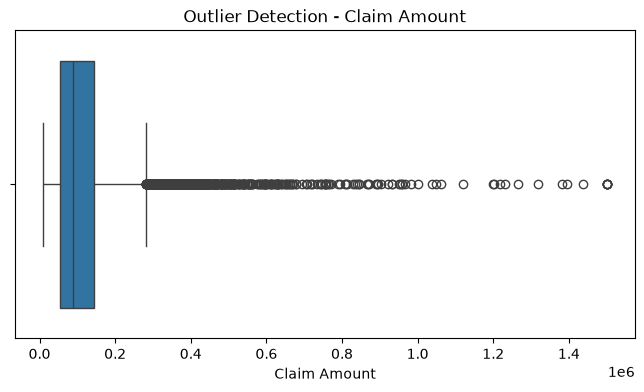

In [47]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=claims["claim_amount"])

plt.title("Outlier Detection - Claim Amount")
plt.xlabel("Claim Amount")

plt.show()

In [48]:
def data_quality_report(datasets):

    report = []

    for name, df in datasets.items():

        report.append({
            "Dataset": name,
            "Total Rows": len(df),
            "Total Columns": len(df.columns),
            "Missing Values": df.isnull().sum().sum(),
            "Duplicate Rows": df.duplicated().sum()
        })

    return pd.DataFrame(report)

In [49]:
quality_report = data_quality_report(datasets)

quality_report

,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows
0,Policies,10000,6,0,0
1,Members,17833,5,0,0
2,Claims,12000,9,0,0
3,Hospitals,100,4,0,0
4,Renewals,10000,4,0,0


In [50]:
for name, df in datasets.items():

    print("\n", "=" * 40)
    print("Dataset:", name)
    print("=" * 40)

    print(df.dtypes)


Dataset: Policies
policy_id                 object
start_date        datetime64[ns]
plan_type                 object
sum_insured                int64
annual_premium             int64
city                      object
dtype: object

Dataset: Members
member_id                 object
policy_id                 object
age_group                 object
gender                    object
pre_existing_condition    object
dtype: object

Dataset: Claims
claim_id                      object
policy_id                     object
member_id                     object
claim_date            datetime64[ns]
hospital_id                   object
treatment_category            object
claim_amount                   int64
approved_amount                int64
claim_status                  object
dtype: object

Dataset: Hospitals
hospital_id    object
city           object
tier           object
network        object
dtype: object

Dataset: Renewals
policy_id                         object
renewal_due_date          

In [51]:
for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Policies: (10000, 6)
Members: (17833, 5)
Claims: (12000, 9)
Hospitals: (100, 4)
Renewals: (10000, 4)


In [52]:
import os

output_folder = "cleaned_datasets"

os.makedirs(output_folder, exist_ok=True)

In [53]:
for name, df in datasets.items():

    file_name = name.lower() + ".csv"

    file_path = os.path.join(output_folder, file_name)

    df.to_csv(file_path, index=False)

    print(f"{name} saved successfully!")

Policies saved successfully!
Members saved successfully!
Claims saved successfully!
Hospitals saved successfully!
Renewals saved successfully!


In [54]:
print("Exported files:")

print(os.listdir(output_folder))

Exported files:
['claims.csv', 'hospitals.csv', 'members.csv', 'policies.csv', 'renewals.csv']


In [55]:
check_policies = pd.read_csv(
    "cleaned_datasets/policies.csv"
)

print(check_policies.head())
print(check_policies.shape)

   policy_id  start_date   plan_type  sum_insured  annual_premium  \
0  POL000001  2025-08-08      Family      2000000           14258   
1  POL000002  2024-12-18      Family      2000000           14509   
2  POL000003  2022-10-30  Individual      1500000            7518   
3  POL000004  2025-12-25  Individual       750000            5116   
4  POL000005  2025-12-21  Individual       750000            3663   

            city  
0          Kochi  
1        Chennai  
2     Coimbatore  
3  Visakhapatnam  
4      Hyderabad  
(10000, 6)
